## Decision Tree:
Creates decision rules inferred from the data, each one as a new leaf node on the tree. Ways to tune: vary max tree depth, pruning strength, or minimum amount of samples required to create a leaf node. 
## Bagging:
Stands for boostrap aggregating. One of our ensemble learning techniques. Many instances of one model trains its own unique subset of the data in parallel. Aggregates (combines) the training results to form decisions. 
## Bagged Decision Tree:
This is essentially a home-made random forest. 
## Random Forest:
Ensemble learning bagging technique. Creates multiple decision trees to train each on its unique subset. Intended to correct overfitting caused by decision trees. 

### Week 6 improved
## Analyze collinearity and correlations in the dataset.
## Drop columns depending on a variance threshold within CV pipeline
## Use smaller data sample on slower fitting models



In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [3]:
covertype = pd.read_csv("../data/covtype.csv")

X = covertype.drop('Cover_Type', axis=1)
y = covertype['Cover_Type']
covertype.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


## Collinearity vs Correlation <br>
Correlation is not the same as collinearity <br>
Correlation measures the statistical association between two variables and can be linear or non linear.<br>
Collinearity refers to a strong linear relationship between multiple predictor variables in a regression model.

In [ ]:
corr_matrix = X.corr(method='pearson')
#threshold of correlation
threshold = 0.2

high_corr = corr_matrix.where((corr_matrix.abs() > threshold) & (corr_matrix != 1.0) )  # everything that is below the threshold or equals 1 (e.g., elevation == elevation equals 1.0) is labelled false. it lets me view the pearson chart more efficiently

print(high_corr)

                                    Elevation    Aspect     Slope  \
Elevation                                 NaN       NaN -0.242697   
Aspect                                    NaN       NaN       NaN   
Slope                               -0.242697       NaN       NaN   
Horizontal_Distance_To_Hydrology     0.306229       NaN       NaN   
Vertical_Distance_To_Hydrology            NaN       NaN  0.274976   
Horizontal_Distance_To_Roadways      0.365559       NaN -0.215914   
Hillshade_9am                             NaN -0.579273 -0.327199   
Hillshade_Noon                       0.205887  0.336103 -0.526911   
Hillshade_3pm                             NaN  0.646944       NaN   
Horizontal_Distance_To_Fire_Points        NaN       NaN       NaN   
Wilderness_Area1                          NaN       NaN -0.234576   
Wilderness_Area2                     0.238164       NaN       NaN   
Wilderness_Area3                          NaN       NaN       NaN   
Wilderness_Area4                  

## Train/test split
I followed the assignment when making these splits for the models that take a lot of time (my prediction: SVC)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

X_train_small = X_train.iloc[0:10000, :]
y_train_small = y_train.iloc[0:10000]
X_test_small = X_test.iloc[0:1000, :]
y_test_small = y_test.iloc[0:1000]
print(X_train.shape, X_test.shape, X_train_small.shape, X_test_small.shape)

(464809, 54) (116203, 54) (10000, 54) (1000, 54)


## Which models are sensitive to collinearity?
- **Linear Discriminant Analysis and Quadratic Discriminant Analysis**: they invert a covariance matrix. Collinear columns make that matrix (nearly) singular.
- **Linear and logistic regression**: coefficients become unstable and hard to interpret (small changes in the data swing them a lot).
- **Naive Bayes**: assumes features are independent given the class, so correlated features get counted twice.
- **Distance based models (KNN, SVC)**: redundant columns give extra weight in the distance metric.
- **Decision trees, bagging, random forests**: not really sensitive for prediction, since each split uses one feature. Feature importance gets split between correlated features though.

## Pairwise correlations
The full 54x54 matrix is too big to read, so I take the upper triangle (each pair once, no diagonal) and list the pairs with |r| > 0.5.

In [8]:
corr_matrix = X_train.corr(method='pearson')

# upper triangle only, so each pair shows up once and the diagonal (always 1) is dropped
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
pairs = upper.stack()
strong_pairs = pairs[pairs.abs() > 0.5].sort_values(key=abs, ascending=False)
print(strong_pairs)
print("pairs with |r| > 0.8:", (pairs.abs() > 0.8).sum())

Wilderness_Area1                  Wilderness_Area3                 -0.793527
Hillshade_9am                     Hillshade_3pm                    -0.780379
Aspect                            Hillshade_3pm                     0.646915
Elevation                         Wilderness_Area4                 -0.619802
Horizontal_Distance_To_Hydrology  Vertical_Distance_To_Hydrology    0.606455
Hillshade_Noon                    Hillshade_3pm                     0.594089
Aspect                            Hillshade_9am                    -0.579131
Wilderness_Area1                  Soil_Type29                       0.550593
Slope                             Hillshade_Noon                   -0.527273
dtype: float64
pairs with |r| > 0.8: 0


### Visualized

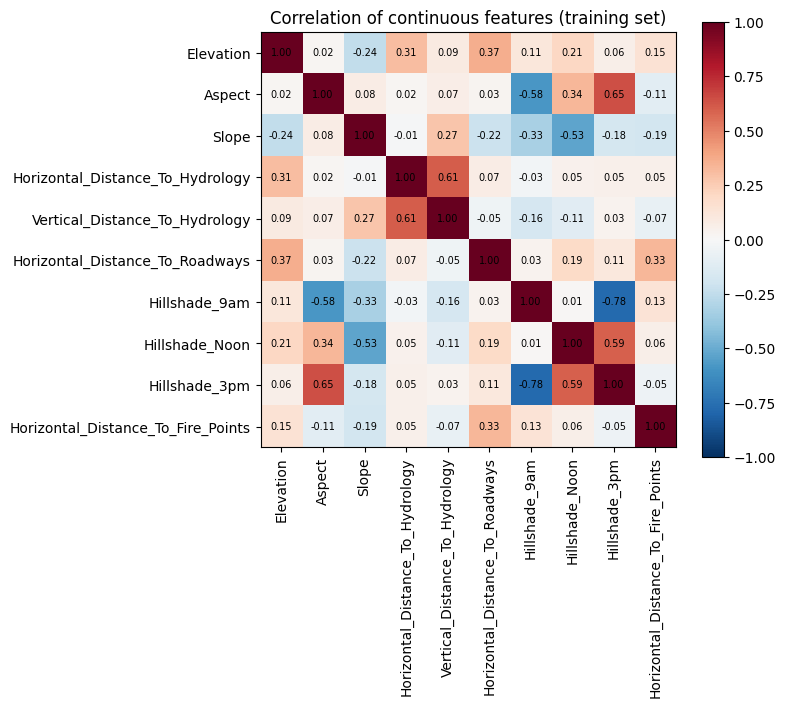

In [9]:
# heatmap of just the 10 continuous features (the rest are 0/1 indicator columns)
continuous_cols = X.columns[:10]
cont_corr = corr_matrix.loc[continuous_cols, continuous_cols]

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cont_corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(continuous_cols)))
ax.set_xticklabels(continuous_cols, rotation=90)
ax.set_yticks(range(len(continuous_cols)))
ax.set_yticklabels(continuous_cols)
for i in range(len(continuous_cols)):
    for j in range(len(continuous_cols)):
        ax.text(j, i, f"{cont_corr.iloc[i, j]:.2f}", ha='center', va='center', fontsize=7)
fig.colorbar(im)
ax.set_title("Correlation of continuous features (training set)")
plt.tight_layout()
plt.show()

### What the pairs mean
- **Wilderness_Area1 vs Wilderness_Area3 (-0.79)**: each row is in exactly one wilderness area, so these are mutually exclusive. When one is 1 the other must be 0.
- **Hillshade_9am vs Hillshade_3pm (-0.78)**, **Aspect vs Hillshade_3pm / 9am**, **Slope vs Hillshade_Noon**: hillshade is computed from the sun angle and the slope's direction (aspect) and steepness. A slope facing east is bright at 9am and dark at 3pm, which explains the negative correlation.
- **Elevation vs Wilderness_Area4 (-0.62)**: Area 4 is the low elevation area.
- **Horizontal vs Vertical_Distance_To_Hydrology (0.61)**: further from water horizontally usually means higher above it too.
- **Wilderness_Area1 vs Soil_Type29 (0.55)**: that soil type mostly occurs in area 1.

No pair is above |r| = 0.8, so judging by pairwise correlation alone the data looks only moderately correlated. The next sections show that this misses the biggest problem.

## Eigenvalues of the correlation matrix
If some combination of predictors is (nearly) constant, then the correlation matrix has an eigenvalue at (or near) 0, and its eigenvector tells us which columns are in that combination.

4 smallest eigenvalues: [-2.26272803e-14 -1.53216666e-15  3.34826415e-03  1.36037897e-01]
largest eigenvalue:    3.6994133503243463


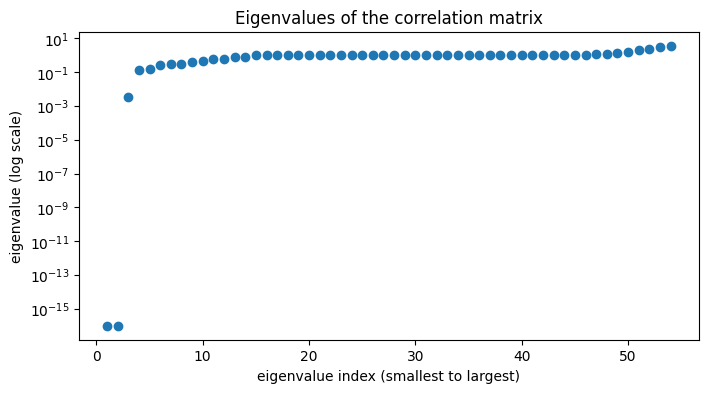

In [10]:
eigvals, eigvecs = np.linalg.eigh(corr_matrix.values)   # eigh because the matrix is symmetric; sorted smallest to largest

print("4 smallest eigenvalues:", eigvals[:4])
print("largest eigenvalue:   ", eigvals[-1])

plt.figure(figsize=(8, 4))
plt.semilogy(range(1, len(eigvals) + 1), np.clip(eigvals, 1e-16, None), 'o')   # clip so the log scale can show the ~0 values
plt.xlabel("eigenvalue index (smallest to largest)")
plt.ylabel("eigenvalue (log scale)")
plt.title("Eigenvalues of the correlation matrix")
plt.show()

In [14]:
# which columns make up the near-zero eigenvalues?
cols = corr_matrix.columns
for k in range(6):
    v = pd.Series(eigvecs[:, k], index=cols)
    share = v**2   # squared loadings sum to 1, so this is each column's share
    print(f"eigenvalue {k+1}: {eigvals[k]:.2e}")
    print("   share on Soil_Type columns:     ", round(share[cols.str.startswith('Soil')].sum(), 3))
    print("   share on Wilderness_Area columns:", round(share[cols.str.startswith('Wilderness')].sum(), 3))
    print("   biggest loadings:", v.abs().sort_values(ascending=False).head(5).round(3).to_dict())

eigenvalue 1: -2.26e-14
   share on Soil_Type columns:      0.108
   share on Wilderness_Area columns: 0.892
   biggest loadings: {'Wilderness_Area1': 0.605, 'Wilderness_Area3': 0.604, 'Wilderness_Area4': 0.297, 'Wilderness_Area2': 0.269, 'Soil_Type29': 0.137}
eigenvalue 2: -1.53e-15
   share on Soil_Type columns:      0.892
   share on Wilderness_Area columns: 0.108
   biggest loadings: {'Soil_Type29': 0.393, 'Soil_Type23': 0.295, 'Soil_Type32': 0.283, 'Soil_Type33': 0.264, 'Soil_Type22': 0.229}
eigenvalue 3: 3.35e-03
   share on Soil_Type columns:      0.0
   share on Wilderness_Area columns: 0.0
   biggest loadings: {'Hillshade_3pm': 0.705, 'Hillshade_9am': 0.598, 'Hillshade_Noon': 0.359, 'Slope': 0.131, 'Soil_Type13': 0.004}
eigenvalue 4: 1.36e-01
   share on Soil_Type columns:      0.429
   share on Wilderness_Area columns: 0.06
   biggest loadings: {'Elevation': 0.663, 'Soil_Type10': 0.308, 'Soil_Type4': 0.19, 'Wilderness_Area1': 0.185, 'Soil_Type29': 0.175}
eigenvalue 5: 1.55e-0

### What the eigenvalues show
- Two eigenvalues are essentially **0** (around 1e-14; tiny negative values are just floating point rounding). Their eigenvectors sit almost entirely on the Wilderness_Area and Soil_Type columns.
- The reason: the 4 Wilderness_Area columns always add up to 1, and so do the 40 Soil_Type columns (checked below). So any one of them can be written exactly as 1 minus the sum of the others. That is **perfect collinearity spread across many columns**, and the pairwise correlations can't show it because no single pair is close to |r| = 1.
- The third smallest eigenvalue (~0.003) is small but not zero, and it sits on Hillshade_9am, Hillshade_3pm, Hillshade_Noon and Slope. That's the hillshade relationship from above, but involving several columns together.

## Condition number
The condition number measures how close the predictors are to being linearly dependent.
- On the correlation matrix it is λ_max / λ_min.
- On the standardized data matrix X it is the square root of that (this is what `np.linalg.cond` of the scaled X gives). Both are the same idea on different scales.

Rule of thumb on the X scale: under ~10 is fine, 10 to 30 is moderate, over ~30 is strong collinearity, and huge values mean the matrix is essentially singular.

First, confirm that the indicator groups really add up to 1:

In [15]:
wilderness_cols = [c for c in X.columns if c.startswith('Wilderness_Area')]
soil_cols = [c for c in X.columns if c.startswith('Soil_Type')]
print("row sums of Wilderness_Area columns:", X_train[wilderness_cols].sum(axis=1).unique())
print("row sums of Soil_Type columns:      ", X_train[soil_cols].sum(axis=1).unique())

row sums of Wilderness_Area columns: [1]
row sums of Soil_Type columns:       [1]


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
print("condition number of scaled X:", np.linalg.cond(X_train_scaled))
print("smallest eigenvalue of correlation matrix:", eigvals[0], "-> effectively 0, so lambda_max / lambda_min is effectively infinite")
print("condition number of correlation matrix (lambda_max / lambda_min):", eigvals[-1] / eigvals[0])

condition number of scaled X: 867093262970592.2
smallest eigenvalue of correlation matrix: -2.2627280330429547e-14 -> effectively 0, so lambda_max / lambda_min is effectively infinite
condition number of correlation matrix (lambda_max / lambda_min): -163493504137539.38


The condition number is enormous, which means the predictors are (numerically) linearly dependent. This is exactly what LDA complains about when it warns that variables are collinear.

## Fix and recheck
The standard fix for one-hot groups is to drop one "reference" column per group. The dropped column isn't lost information, since it is 1 exactly when all the others in its group are 0.

In [18]:
X_train_dropped = X_train.drop(columns=['Wilderness_Area4', 'Soil_Type40'])
corr_dropped = X_train_dropped.corr()
eigvals_dropped, eigvecs_dropped = np.linalg.eigh(corr_dropped.values)

print("6 smallest eigenvalues after dropping:", eigvals_dropped[:6])
print("condition number of correlation matrix (lambda_max / lambda_min):", eigvals_dropped[-1] / eigvals_dropped[0])
print("condition number of scaled X:", np.linalg.cond(StandardScaler().fit_transform(X_train_dropped)))
print("biggest loadings of the smallest eigenvalue:",
      pd.Series(eigvecs_dropped[:, 0], index=corr_dropped.columns).abs().sort_values(ascending=False).head(4).round(3).to_dict())

6 smallest eigenvalues after dropping: [0.00334807 0.0137672  0.03107564 0.15505174 0.22030973 0.25260291]
condition number of correlation matrix (lambda_max / lambda_min): 1055.5626652700028
condition number of scaled X: 32.48942389871089
biggest loadings of the smallest eigenvalue: {'Hillshade_3pm': 0.704, 'Hillshade_9am': 0.598, 'Hillshade_Noon': 0.359, 'Slope': 0.131}


### After dropping
- The two zero eigenvalues are gone, and the condition number drops from effectively infinite to about 1,000 on the correlation matrix (about 32 on the X scale).
- About 32 is right at the "strong" cutoff. What's left is the hillshade/slope relationship, since hillshade is largely a function of slope and aspect. Models like LDA and QDA can work with this, but it is still worth knowing about.
- Dropping low variance soil columns (the next part of the assignment) also removes columns that are almost always 0, which is related: a column that is nearly constant is nearly collinear with the intercept.

## Summary: correlation and collinearity
- **Pairwise correlation**: 9 pairs have |r| > 0.5 and none have |r| > 0.8. The strongest are Wilderness_Area1/Wilderness_Area3 (-0.79) and Hillshade_9am/Hillshade_3pm (-0.78).
- **Collinearity**: much worse than the pairwise numbers suggest. The Wilderness_Area and Soil_Type groups each sum to 1, giving two eigenvalues of 0 and an effectively infinite condition number. This is a relationship among many columns at once, which pairwise correlation can't detect.
- **Fix**: dropping one column per group brings the condition number down to about 32 (X scale). The remaining collinearity comes from the hillshade, aspect and slope columns.
- **Who cares**: LDA, QDA, Naive Bayes, linear/logistic regression and distance based models (KNN, SVC). Decision trees, bagging and random forests are largely unaffected.

# LDA, QDA and Naive Bayes with a variance threshold
## The variance threshold
A 0/1 column that is 1 with probability p has variance p(1-p). With p = 5% that's 0.05 * 0.95 = **0.0475**, so `VarianceThreshold(0.0475)` drops every indicator column that is 1 (or 0) in fewer than 5% of rows.
- The continuous columns (elevation, distances, etc.) have variances in the hundreds or thousands, so only the indicator columns can get dropped.
- The threshold has to come **before** scaling. StandardScaler would make every column's variance 1, and the threshold would drop nothing.
- After the threshold I use MinMaxScaler, which leaves the 0/1 columns unchanged (as the assignment points out) and puts the continuous columns on a 0 to 1 scale.

These three models are fast, so this part uses the full training set (about 465,000 rows) with 5-fold stratified CV. Stratified keeps the class proportions the same in every fold, which matters because the classes are imbalanced.

In [20]:
import time
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB

threshold = 0.05 * (1 - 0.05)   # 0.0475
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# just to see how many columns survive (fit on the training set only)
selector = VarianceThreshold(threshold).fit(X_train)
print("columns kept:", selector.get_support().sum(), "of", X_train.shape[1])

columns kept: 22 of 54


## Should we tune these models?
The assignment doesn't ask for it, and LDA has nothing worth tuning. But QDA and Naive Bayes each have one setting that turns out to matter a lot on this data:
- **QDA `reg_param`**: QDA estimates a separate covariance matrix per class. Many 0/1 columns never change within some class (e.g. a soil type that never shows up for that tree type), so that covariance matrix can't be inverted. `reg_param` shrinks it toward the identity so it can. With `reg_param=0` QDA basically falls apart.
- **Naive Bayes `var_smoothing`**: GaussianNB fits a bell curve to every column per class. A 0/1 column that is almost always 0 in a class gets a tiny variance, so a single 1 makes that class look nearly impossible. `var_smoothing` adds a bit of variance to every column to soften this.

Both are a single parameter, so a small grid search is cheap. I tune them the right way, with the threshold inside the pipeline.

In [21]:
qda_search = GridSearchCV(
    make_pipeline(VarianceThreshold(threshold), MinMaxScaler(), QuadraticDiscriminantAnalysis()),
    param_grid={'quadraticdiscriminantanalysis__reg_param': [0, 0.001, 0.01, 0.1, 0.5]},
    cv=cv)
nb_search = GridSearchCV(
    make_pipeline(VarianceThreshold(threshold), MinMaxScaler(), GaussianNB()),
    param_grid={'gaussiannb__var_smoothing': [1e-9, 1e-6, 1e-3, 1e-1, 1, 3]},
    cv=cv)

start = time.time()
qda_search.fit(X_train, y_train)
print(f"QDA search took {time.time() - start:.1f} s")
start = time.time()
nb_search.fit(X_train, y_train)
print(f"NB search took {time.time() - start:.1f} s")

for name, search in [("QDA", qda_search), ("NB", nb_search)]:
    results = pd.DataFrame(search.cv_results_)
    param_col = [c for c in results.columns if c.startswith('param_')][0]
    print(f"\n{name}: best {search.best_params_}")
    results['mean_test_score'] = results['mean_test_score'].round(4)
    print(results[[param_col, 'mean_test_score']].to_string(index=False))

best_reg_param = qda_search.best_params_['quadraticdiscriminantanalysis__reg_param']
best_var_smoothing = nb_search.best_params_['gaussiannb__var_smoothing']

c:\Users\owner\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
c:\Users\owner\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
c:\Users\owner\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 2 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
c:\Users\owner\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 3 is 

QDA search took 19.4 s
NB search took 18.8 s

QDA: best {'quadraticdiscriminantanalysis__reg_param': 0.1}
 param_quadraticdiscriminantanalysis__reg_param  mean_test_score
                                          0.000           0.0161
                                          0.001           0.4254
                                          0.010           0.5153
                                          0.100           0.6053
                                          0.500           0.5185

NB: best {'gaussiannb__var_smoothing': 1}
 param_gaussiannb__var_smoothing  mean_test_score
                    1.000000e-09           0.1459
                    1.000000e-06           0.1705
                    1.000000e-03           0.3452
                    1.000000e-01           0.5145
                    1.000000e+00           0.5817
                    3.000000e+00           0.4911


### Tuning results
- **QDA**: `reg_param=0` gives about 2% accuracy (worse than guessing), because the per-class covariance matrices can't be inverted. Accuracy climbs to about 60% at `reg_param=0.1` and drops again at 0.5, where it shrinks so much it starts to throw away the per-class information. So 0.1 it is.
- **Naive Bayes**: the default `var_smoothing=1e-9` gives about 15%. Accuracy rises steadily to about 58% at `var_smoothing=1` and falls at 3, so the best value is bracketed.

So tuning these two models was clearly worth it, even though it wasn't required.

## Wrong way vs right way
- **Wrong way**: fit the variance threshold on the whole training set, then cross validate on the reduced data. The threshold has already seen the validation folds, so information leaks from them.
- **Right way**: put the threshold inside the pipeline, so in each fold it is fit only on that fold's training part.

I also run each model with **no threshold** (all 54 columns) to see whether dropping the columns helped at all.

For bias/variance I use `return_train_score=True`:
- **train accuracy vs CV accuracy**: a big gap means overfitting (high variance), no gap means the model is too simple to overfit (high bias).
- **std of CV accuracy across folds**: how much the score moves when the training data changes.

In [22]:
models = {
    'LDA': LinearDiscriminantAnalysis(),
    'QDA': QuadraticDiscriminantAnalysis(reg_param=best_reg_param),
    'Naive Bayes': GaussianNB(var_smoothing=best_var_smoothing),
}

def run_cv(pipe, X_data):
    start = time.time()
    scores = cross_validate(pipe, X_data, y_train, cv=cv, return_train_score=True)
    return scores, time.time() - start

rows = []
for name, model in models.items():
    # no threshold: all columns
    scores, secs = run_cv(make_pipeline(MinMaxScaler(), model), X_train)
    rows.append((name, 'no threshold', scores, secs))

    # wrong way: threshold fit once on all of X_train, before CV (time includes that fit)
    start = time.time()
    X_train_reduced = VarianceThreshold(threshold).fit_transform(X_train)
    pre_secs = time.time() - start
    scores, secs = run_cv(make_pipeline(MinMaxScaler(), model), X_train_reduced)
    rows.append((name, 'wrong way (before CV)', scores, secs + pre_secs))

    # right way: threshold inside the pipeline, refit in every fold
    scores, secs = run_cv(make_pipeline(VarianceThreshold(threshold), MinMaxScaler(), model), X_train)
    rows.append((name, 'right way (inside CV)', scores, secs))

comparison = pd.DataFrame([{
    'model': name,
    'version': version,
    'train acc': s['train_score'].mean(),
    'CV acc': s['test_score'].mean(),
    'train - CV gap': s['train_score'].mean() - s['test_score'].mean(),
    'CV std': s['test_score'].std(),
    'total seconds': secs,
} for name, version, s, secs in rows])
comparison.round(4)

,model,version,train acc,CV acc,train - CV gap,CV std,total seconds
0,LDA,no threshold,0.6797,0.6798,-0.0000,0.0005,9.6891
1,LDA,wrong way (before CV),0.6727,0.6725,0.0002,0.0008,3.6632
2,LDA,right way (inside CV),0.6727,0.6725,0.0002,0.0008,4.4500
3,QDA,no threshold,0.6309,0.6308,0.0001,0.0015,13.9957
4,QDA,wrong way (before CV),0.6054,0.6053,0.0001,0.0008,5.5548
5,QDA,right way (inside CV),0.6054,0.6053,0.0001,0.0008,6.4132
6,Naive Bayes,no threshold,0.6124,0.6124,0.0000,0.0008,9.5782
7,Naive Bayes,wrong way (before CV),0.5818,0.5817,0.0001,0.0007,4.8427
8,Naive Bayes,right way (inside CV),0.5818,0.5817,0.0001,0.0007,5.4255


### What the comparison shows
**Accuracy:** the variance threshold made all three models slightly *worse*:
- LDA: 68.0% → 67.3%
- QDA: 63.1% → 60.5%
- Naive Bayes: 61.2% → 58.2%

The dropped soil types are rare, but when they do show up they say something about the tree type, so a little information is lost. (Without tuning, Naive Bayes did *improve* with the threshold, from about 9% to 15%, because the rare columns were what broke it. Once `var_smoothing` fixes that problem, the threshold is no longer needed.)

**Training time:** dropping 32 of the 54 columns cut the CV time roughly in half for every model (for example LDA 9 s → 3 to 4 s).

**Wrong way vs right way:** identical accuracy, and the right way is about 1 second slower because it refits the threshold in every fold. They match here because:
- the threshold doesn't look at y, so it can't leak information about the labels, and
- with about 370,000 rows in each fold, every fold picks the same 22 columns.

On a small dataset the columns kept could change from fold to fold, and only the right way would capture that. It's the correct habit either way, and the extra cost is small.

**Bias/variance:** train and CV accuracy are within 0.03% of each other, and the fold-to-fold std is under 0.2%. These models have **high bias and low variance**: they are too simple to overfit, and too simple to fit the data well (best is about 68%). More flexible models like decision trees and random forests should do much better, which is what the next part tests.

**Test set:** the test accuracies (LDA 67.1%, QDA 60.4%, NB 58.1%) match the CV estimates, which is expected for low variance models.

## Final check on the test set
Using the right way pipelines, fit on the whole training set and score once on the held out test set.

In [23]:
for name, model in models.items():
    pipe = make_pipeline(VarianceThreshold(threshold), MinMaxScaler(), model)
    start = time.time()
    pipe.fit(X_train, y_train)
    fit_secs = time.time() - start
    print(f"{name:12s} test accuracy: {pipe.score(X_test, y_test):.4f}   (fit took {fit_secs:.1f} s)")

LDA          test accuracy: 0.6708   (fit took 0.9 s)
QDA          test accuracy: 0.6043   (fit took 0.7 s)
Naive Bayes  test accuracy: 0.5808   (fit took 0.5 s)


## Summary: variance threshold with LDA, QDA and Naive Bayes
- `VarianceThreshold(0.0475)` keeps 22 of 54 columns (all 10 continuous columns plus the 12 indicator columns that are 1 in at least 5% of rows).
- It halves training time but costs 1 to 3 points of accuracy for each model.
- Doing it inside the CV pipeline (the right way) gives the same scores here and costs about 1 extra second.
- LDA is the best of the three at about 67 to 68%. All three are high bias, low variance models.
- Tuning mattered: QDA needs `reg_param` (0.1) and Naive Bayes needs `var_smoothing` (1), or they barely work on this data.

# Decision trees, bagged trees and random forests
These are the main models for this assignment. Tuning them means fitting each one many times (5 folds x every parameter combination), so following the assignment and the feedback, this part uses the **10,000-row training sample** and the **1,000-row test sample**.

**Preprocessing:** trees don't need scaling (a split like `Elevation < 2900` works the same on any scale), and they aren't hurt by collinearity, so all 54 columns go in as they are. A variance threshold isn't needed either, since a tree just never splits on a column that doesn't help.

**How I measure bias/variance:** `return_train_score=True` gives the accuracy on the data the model was trained on, next to the CV accuracy on data it hasn't seen.
- Train accuracy much higher than CV accuracy → the model memorized the training data → **high variance (overfitting)**.
- Both low and close together -> the model is too simple -> **high bias (underfitting)**.

`n_jobs=-1` runs the CV folds in parallel on all CPU cores to save time.

In [24]:
y_train_small.value_counts().sort_index()

Cover_Type
1    3629
2    4859
3     594
4      60
5     175
6     305
7     378
Name: count, dtype: int64

The sample keeps the class imbalance of the full data: classes 1 and 2 are about 85% of the rows and class 4 has only 60 rows. Stratified CV keeps these proportions the same in each fold.

In [26]:
def show_search(search, name):
    # summary of a fitted GridSearchCV: one row per parameter combination
    results = pd.DataFrame(search.cv_results_)
    param_cols = [c for c in results.columns if c.startswith('param_')]
    table = results[param_cols + ['mean_train_score', 'mean_test_score', 'std_test_score', 'mean_fit_time']].copy()
    table.columns = [c.replace('param_', '') for c in param_cols] + ['train acc', 'CV acc', 'CV std', 'fit seconds']
    print(f"{name}: best {search.best_params_}, CV accuracy {search.best_score_:.4f}")
    return table.round(4)

## Decision tree
Tuning two settings that both control how complex the tree gets:
- `max_depth`: how many levels of splits the tree can have (`None` = grow until every leaf is pure)
- `min_samples_leaf`: the minimum number of training rows in a leaf. Bigger values stop the tree from making leaves for just one or two rows.

In [27]:
tree_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid={'max_depth': [2, 4, 6, 8, 10, 15, 20, None], 'min_samples_leaf': [1, 5, 20]},
    cv=cv, return_train_score=True, n_jobs=-1)

start = time.time()
tree_search.fit(X_train_small, y_train_small)
print(f"search took {time.time() - start:.1f} s")
show_search(tree_search, "Decision tree")

search took 11.4 s
Decision tree: best {'max_depth': 15, 'min_samples_leaf': 1}, CV accuracy 0.7268


,max_depth,min_samples_leaf,train acc,CV acc,CV std,fit seconds
0,2,1,0.6710,0.6658,0.0045,0.0663
1,2,5,0.6710,0.6658,0.0045,0.0669
2,2,20,0.6710,0.6658,0.0045,0.0643
3,4,1,0.7046,0.6908,0.0087,0.0843
4,4,5,0.7046,0.6908,0.0087,0.0837
5,4,20,0.7040,0.6906,0.0083,0.0423
6,6,1,0.7383,0.7092,0.0106,0.0512
7,6,5,0.7367,0.7085,0.0108,0.0594
8,6,20,0.7309,0.7060,0.0127,0.0497
9,8,1,0.7786,0.7208,0.0086,0.0660


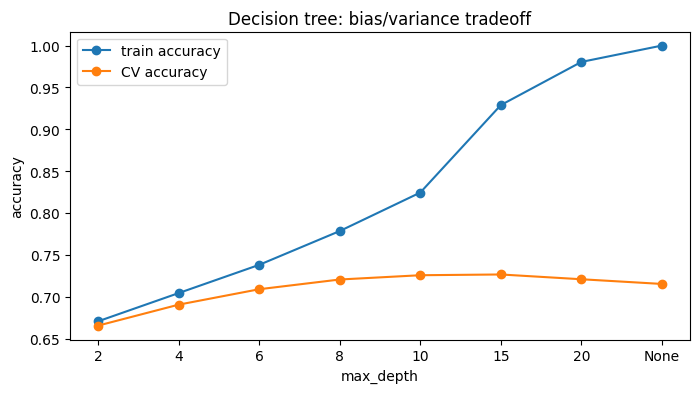

In [28]:
# train vs CV accuracy as the tree gets deeper (min_samples_leaf=1)
tree_results = pd.DataFrame(tree_search.cv_results_)
leaf1 = tree_results[tree_results['param_min_samples_leaf'] == 1]
depth_labels = [str(d) for d in leaf1['param_max_depth']]

plt.figure(figsize=(8, 4))
plt.plot(depth_labels, leaf1['mean_train_score'], 'o-', label='train accuracy')
plt.plot(depth_labels, leaf1['mean_test_score'], 'o-', label='CV accuracy')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.title('Decision tree: bias/variance tradeoff')
plt.legend()
plt.show()

### Decision tree results
- **Shallow trees (depth 2 to 4): high bias.** Train and CV accuracy are both low (about 67 to 70%) and close together. The tree is too simple.
- **Deep trees (depth 20 to None): high variance.** Train accuracy goes to 98 to 100% but CV accuracy *drops* to about 72%. The tree is memorizing individual training rows.
- **In between (depth 10 to 15)** is the sweet spot, at about 72.7% CV accuracy. The best is `max_depth=15, min_samples_leaf=1`.
- `min_samples_leaf` limits overfitting too (at depth None, train accuracy drops from 100% to 79% with `min_samples_leaf=20`), but it doesn't beat the depth limit on CV accuracy.
- Even the best tree still has a 20 point gap between train (93%) and CV (73%). A single tree is a high variance model, which is exactly the problem bagging and random forests are designed to fix.
- Training is very fast: about 0.1 s per fit.

## Bagged decision trees
Bagging trains many full-depth trees, each on a bootstrap sample (random rows drawn with replacement), and lets them vote. Each tree overfits in its own way, so averaging cancels a lot of the noise. This lowers variance without adding bias.

Tuning `n_estimators` (the number of trees). `n_estimators=1` is a single bootstrapped tree, as a baseline.

In [30]:
bag_search = GridSearchCV(
    BaggingClassifier(DecisionTreeClassifier(), random_state=42),
    param_grid={'n_estimators': [1, 5, 10, 25, 50, 100]},
    cv=cv, return_train_score=True, n_jobs=-1)

start = time.time()
bag_search.fit(X_train_small, y_train_small)
print(f"search took {time.time() - start:.1f} s")
show_search(bag_search, "Bagged trees")

search took 13.4 s
Bagged trees: best {'n_estimators': 100}, CV accuracy 0.8019


,n_estimators,train acc,CV acc,CV std,fit seconds
0,1,0.8824,0.6900,0.0059,0.0915
1,5,0.9716,0.7589,0.0037,0.3933
2,10,0.9876,0.7767,0.0060,0.7796
3,25,0.9982,0.7912,0.0054,1.8144
4,50,0.9997,0.8000,0.0045,3.3557
5,100,1.0000,0.8019,0.0062,6.0688


## Random forest
A random forest is bagging plus one extra trick: at each split, a tree may only choose from a random subset of the columns. That makes the trees less alike, so their errors cancel out better when they vote.

Tuning two settings:
- `n_estimators`: number of trees
- `max_features`: how many columns each split gets to choose from (`'sqrt'` = sqrt(54) ≈ 7 columns, 0.3 = 30% ≈ 16 columns, 0.6 = 60% ≈ 32 columns)

In [33]:
forest_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid={'n_estimators': [1, 5, 10, 25, 50, 100, 200], 'max_features': ['sqrt', 0.3, 0.6]},
    cv=cv, return_train_score=True, n_jobs=-1)

start = time.time()
forest_search.fit(X_train_small, y_train_small)
print(f"search took {time.time() - start:.1f} s")
show_search(forest_search, "Random forest")

search took 16.0 s
Random forest: best {'max_features': 0.3, 'n_estimators': 200}, CV accuracy 0.8101


,max_features,n_estimators,train acc,CV acc,CV std,fit seconds
0,sqrt,1,0.8749,0.6545,0.0086,0.0306
1,sqrt,5,0.9712,0.7468,0.0114,0.1034
2,sqrt,10,0.9895,0.7729,0.0069,0.1893
3,sqrt,25,0.9988,0.7928,0.0070,0.4485
4,sqrt,50,0.9999,0.7953,0.0053,0.9232
5,sqrt,100,1.0000,0.8015,0.0044,1.7492
6,sqrt,200,1.0000,0.8020,0.0022,3.4089
7,0.3,1,0.8830,0.6772,0.0072,0.0358
8,0.3,5,0.9716,0.7604,0.0075,0.1536
9,0.3,10,0.9886,0.7811,0.0067,0.2793


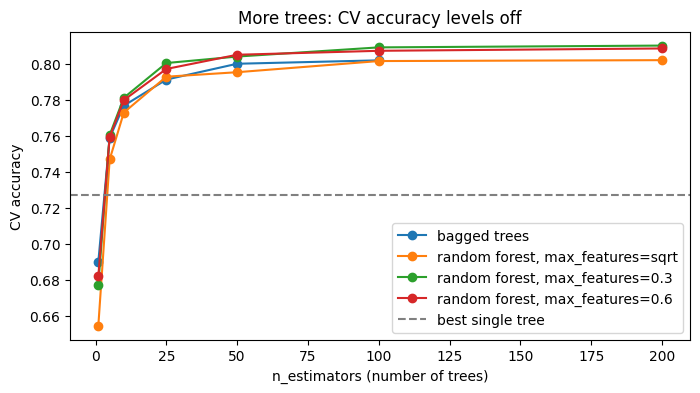

In [34]:
# CV accuracy vs number of trees, for bagging and each max_features setting of the random forest
bag_results = pd.DataFrame(bag_search.cv_results_)
forest_results = pd.DataFrame(forest_search.cv_results_)

plt.figure(figsize=(8, 4))
plt.plot(bag_results['param_n_estimators'], bag_results['mean_test_score'], 'o-', label='bagged trees')
for mf in ['sqrt', 0.3, 0.6]:
    rows = forest_results[forest_results['param_max_features'] == mf]
    plt.plot(rows['param_n_estimators'], rows['mean_test_score'], 'o-', label=f'random forest, max_features={mf}')
plt.axhline(tree_search.best_score_, color='gray', linestyle='--', label='best single tree')
plt.xlabel('n_estimators (number of trees)')
plt.ylabel('CV accuracy')
plt.title('More trees: CV accuracy levels off')
plt.legend()
plt.show()

### Bagging and random forest results
- **Adding trees helps, then levels off.** Bagging goes from 69% (1 tree) to 78% (10 trees) to about 80% (50 to 100 trees). More trees can't overfit; they just stop helping, while training time keeps growing in proportion to the number of trees.
- **Random forest is a little better than bagging** (about 81% vs 80%). `max_features=0.3` was best: `'sqrt'` (7 columns) is a bit too restrictive here, and 0.6 makes the trees more alike, so they look more like plain bagging.
- **Train accuracy is 100% for both, which doesn't mean they overfit badly.** Each tree is grown to full depth, so the ensemble always fits its own training rows perfectly. What matters is CV accuracy, which went *up* by about 8 points over the best single tree. That gain is the variance reduction from averaging many trees.

## Comparing the tuned models
CV accuracy is from the grid search. Training time is one fit of the best model on the 10,000-row sample, on a single CPU core so the times are fair to compare. Test accuracy is on the 1,000-row test sample. With only 1,000 rows each test accuracy is only accurate to about ±1.5 points, so small differences there are noise.

In [35]:
best_models = {
    'Decision tree': tree_search,
    'Bagged trees': bag_search,
    'Random forest': forest_search,
}

summary_rows = []
for name, search in best_models.items():
    model = search.best_estimator_   # n_jobs defaults to 1 core for all three
    start = time.time()
    model.fit(X_train_small, y_train_small)
    fit_secs = time.time() - start
    results = pd.DataFrame(search.cv_results_).iloc[search.best_index_]
    summary_rows.append({
        'model': name,
        'best params': search.best_params_,
        'train acc': results['mean_train_score'],
        'CV acc': results['mean_test_score'],
        'train - CV gap': results['mean_train_score'] - results['mean_test_score'],
        'fit seconds (1 core)': fit_secs,
        'test acc': model.score(X_test_small, y_test_small),
    })

tree_summary = pd.DataFrame(summary_rows)
tree_summary.round(4)

,model,best params,train acc,CV acc,train - CV gap,fit seconds (1 core),test acc
0,Decision tree,"{'max_depth': 15, 'min_samples_leaf': 1}",0.929,0.7268,0.2022,0.0841,0.734
1,Bagged trees,{'n_estimators': 100},1.000,0.8019,0.1981,6.4747,0.796
2,Random forest,"{'max_features': 0.3, 'n_estimators': 200}",1.000,0.8101,0.1899,4.4879,0.802


# Comparing with SVC
SVC is the slowest model here: kernel SVC compares training rows with each other, so its training time grows roughly with the *square* of the number of rows or worse. It's fine on 10,000 rows and hopeless on the full 465,000, so this uses the same samples as the tree models.

**Preprocessing matters a lot for SVC.** It works with distances, so it needs scaled data. I use MinMaxScaler (inside the pipeline, so it's fit on each training fold only), which leaves the 0/1 columns unchanged.

Tuning:
- `kernel`: `'linear'` (a straight boundary between classes) vs `'rbf'` (a curved, flexible boundary)
- `C`: how hard the model tries to classify every training row correctly. Small C = smoother boundary (more bias), large C = boundary bends around individual points (more variance).

In [36]:
from sklearn.svm import SVC

svc_search = GridSearchCV(
    make_pipeline(MinMaxScaler(), SVC()),
    # C=1000 only for rbf: the linear kernel gets very slow at large C
    param_grid=[{'svc__kernel': ['linear'], 'svc__C': [0.1, 1, 10, 100]},
                {'svc__kernel': ['rbf'], 'svc__C': [0.1, 1, 10, 100, 1000]}],
    cv=cv, return_train_score=True, n_jobs=-1)

start = time.time()
svc_search.fit(X_train_small, y_train_small)
print(f"search took {time.time() - start:.1f} s")
show_search(svc_search, "SVC")

search took 31.5 s
SVC: best {'svc__C': 1000, 'svc__kernel': 'rbf'}, CV accuracy 0.7731


,svc__C,svc__kernel,train acc,CV acc,CV std,fit seconds
0,0.1,linear,0.6768,0.6730,0.0070,4.3537
1,1.0,linear,0.7248,0.7218,0.0059,4.3204
2,10.0,linear,0.7342,0.7282,0.0048,5.8179
3,100.0,linear,0.7378,0.7287,0.0046,11.0825
4,0.1,rbf,0.6529,0.6513,0.0072,6.2929
5,1.0,rbf,0.7379,0.7272,0.0062,4.8294
6,10.0,rbf,0.7682,0.7471,0.0042,3.5162
7,100.0,rbf,0.8123,0.7673,0.0019,4.1352
8,1000.0,rbf,0.8546,0.7731,0.0109,5.5722


### SVC results
- **Kernel matters.** The linear kernel tops out at about 73% no matter how large C gets, close to LDA. A straight boundary just can't separate these classes well. The rbf kernel keeps improving as C grows, up to about 77% at C=1000.
- **C is a bias/variance knob.** For rbf, C=0.1 underfits (train 65%, CV 65%: high bias). As C grows, train accuracy rises faster than CV accuracy: the gap goes from 0% at C=0.1 to 4.5% at C=100 to 8% at C=1000. Larger C fits the training data more closely, so variance goes up. C=1000 is still the best on CV, but the gains are getting small.
- **Training time:** each fit takes a few seconds on 10,000 rows. (The `fit seconds` in the grid tables are higher than a normal fit because all the folds run in parallel and share the CPU.)
- **Why SVC took forever in my first attempt:** with StandardScaler instead of MinMaxScaler, the linear kernel gets very slow as C grows. In a test, C=10 took 34 s per fit instead of about 2 s, and it gets slower still as C grows. Multiply that by 5 folds and several C values and a grid search can run for a very long time. Scaling to 0 to 1 keeps the solver fast, and the sample keeps the data small.
- SVC beats the single decision tree but not bagging or the random forest.

## All models on the 10,000-row sample
LDA, QDA and Naive Bayes are refit on the same sample (with the settings found earlier) so every model is compared on the same data.

In [37]:
all_models = {
    'LDA': make_pipeline(MinMaxScaler(), LinearDiscriminantAnalysis()),
    'QDA': make_pipeline(MinMaxScaler(), QuadraticDiscriminantAnalysis(reg_param=best_reg_param)),
    'Naive Bayes': make_pipeline(MinMaxScaler(), GaussianNB(var_smoothing=best_var_smoothing)),
    'Decision tree': tree_search.best_estimator_,
    'Bagged trees': bag_search.best_estimator_,
    'Random forest': forest_search.best_estimator_,
    'SVC': svc_search.best_estimator_,
}

final_rows = []
for name, model in all_models.items():
    scores = cross_validate(model, X_train_small, y_train_small, cv=cv, return_train_score=True, n_jobs=-1)
    start = time.time()
    model.fit(X_train_small, y_train_small)
    fit_secs = time.time() - start
    final_rows.append({
        'model': name,
        'train acc': scores['train_score'].mean(),
        'CV acc': scores['test_score'].mean(),
        'train - CV gap': scores['train_score'].mean() - scores['test_score'].mean(),
        'fit seconds (1 core)': fit_secs,
        'test acc': model.score(X_test_small, y_test_small),
    })

final_comparison = pd.DataFrame(final_rows).sort_values('CV acc', ascending=False)
final_comparison.round(4)

,model,train acc,CV acc,train - CV gap,fit seconds (1 core),test acc
5,Random forest,1.0000,0.8101,0.1899,4.4192,0.802
4,Bagged trees,1.0000,0.8019,0.1981,6.5447,0.796
6,SVC,0.8546,0.7731,0.0815,4.6001,0.773
3,Decision tree,0.9290,0.7268,0.2022,0.0856,0.734
0,LDA,0.6841,0.6808,0.0033,0.0460,0.654
1,QDA,0.6388,0.6335,0.0053,0.0450,0.621
2,Naive Bayes,0.6163,0.6153,0.0010,0.0100,0.612


## Conclusion
- **Best model: random forest** (`max_features=0.3`, 200 trees) at about 81% CV accuracy and 80% on the test sample, followed closely by bagged trees (80%). Both beat the best single tree by about 8 points, and beat LDA, QDA and Naive Bayes by 13 to 20 points.
- **Bias/variance:**
  - LDA, QDA and Naive Bayes are high bias: train and CV accuracy are equal and low. They're too simple for this data.
  - A single decision tree is high variance: it fits the training data well (93% for the best depth, 100% unrestricted) but only gets about 73% on new data. Limiting the depth trades a bit of that variance for bias.
  - Bagging and random forests keep the low bias of deep trees and cut the variance by averaging many of them, which is why they score highest. Their 100% train accuracy is expected for full-depth trees and isn't a sign of a problem, since their CV accuracy is the best of all.
  - SVC sits in between, with C controlling the tradeoff.
- **Training time (one fit on 10,000 rows, one CPU core):** Naive Bayes, LDA, QDA and the single tree take under 0.2 s. SVC takes a few seconds. Bagging (100 trees) and the random forest (200 trees) take about 5 to 10 s. Ensembles cost roughly (number of trees) x (one tree), but each tree can run on its own core with `n_jobs=-1`.
- **Accuracy vs time:** the random forest is both the most accurate and faster than bagging, since each split only looks at 30% of the columns.
- All tuning used the 10,000-row sample as the assignment suggests. With the full 465,000 rows the tree ensembles would likely do better still (they benefit from more data and are still practical to train), while SVC would become far too slow.